# CIS468- Regression Analysis
Claudia dela Paz


In [11]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


### dataset description
Source: Kaggle
The dataset simulates a survey of secondary-school students. It has 29 columns and 12,000 observations (rows)It features socioeconomic features such as income, family, residential area, etc. It also includes behavioral and school features such as study hours, attendance, tutoring, etc. The outcome variable is the grade % and letter grade class, which will be used in regression.

the target variable is final_grade_pct

In [ ]:
#import dataset
dataset = pd.read_csv('student_grade_ses_dataset.csv')
dataset[0:20]

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0
5,STU106506,2022-2023,2025-04-07,18,Male,12,Government,Rural,4,1,...,5.6,No Scholarship,0,2,12.8,85.4,76.6,88.3,B,0
6,STU100268,2021-2022,2025-03-14,14,Female,10,Government,Urban,5,3,...,0.7,No Scholarship,0,3,16.9,89.2,44.6,42.1,D,0
7,STU110359,2021-2022,2025-04-07,14,Male,9,Government,Rural,6,3,...,1.3,No Scholarship,0,3,15.8,89.9,57.2,71.1,C,0
8,STU109652,2021-2022,2025-03-22,16,Female,11,Government,Semi-Urban,5,2,...,3.3,No Scholarship,0,3,13.4,83.8,56.5,63.1,C,0
9,STU103794,2023-2024,2025-03-20,16,Female,12,Government,Rural,4,2,...,18.0,No Scholarship,0,2,13.5,94.8,67.1,81.3,B,0


assignment requirements:
Choose a dataset that is of interest to you and is well suited for regression
1. Describe the dataset
2. Perform EDA to understand the variables of the dataset.
3. Research at least 3 different regression models. There are many regression models available for
Python Sklearn package or use keras MLP or CNN we introduced in class.
4. Give an explanation of the model that you are using.
5. Design an experiment using training and testing (holdout method), cross-validation method.
6. Try using generative AI to improve your model
7. Compare the results of three or more regression methods using the same experimental setup using
2 or more regression evaluation metrics discussed in class.

In [13]:
print(dataset.head())

  student_id academic_year survey_date  age  gender  grade_level  \
0  STU101529     2024-2025  2025-03-06   16    Male           12   
1  STU107546     2022-2023  2025-05-02   15    Male           10   
2  STU103737     2024-2025  2025-03-21   14    Male            9   
3  STU108172     2023-2024  2025-03-30   13    Male            8   
4  STU110633     2023-2024  2025-05-06   11  Female            6   

       school_type residence_type  family_size  num_siblings  ...  \
0       Government          Rural            3             0  ...   
1       Government          Urban            3             1  ...   
2       Government          Urban            2             0  ...   
3       Government          Rural            6             4  ...   
4  Private-Unaided          Rural            5             3  ...   

   distance_to_school_km scholarship_status  extra_tutoring  \
0                    4.0     No Scholarship               0   
1                    0.7     No Scholarship       

In [14]:
# see datatset types
dataset.dtypes

student_id                        str
academic_year                     str
survey_date                       str
age                             int64
gender                            str
grade_level                     int64
school_type                       str
residence_type                    str
family_size                     int64
num_siblings                    int64
single_parent_household         int64
family_income_bracket             str
annual_family_income_inr      float64
father_education_level            str
mother_education_level            str
father_occupation                 str
mother_occupation                 str
has_internet_access           float64
has_computer_or_laptop          int64
distance_to_school_km         float64
scholarship_status                str
extra_tutoring                  int64
parental_involvement_score      int64
study_hours_per_week          float64
attendance_rate_pct           float64
previous_year_grade_pct       float64
final_grade_

In [15]:
print(dataset.isnull().sum()) #check for null values

student_id                      0
academic_year                   0
survey_date                     0
age                             0
gender                          0
grade_level                     0
school_type                     0
residence_type                  0
family_size                     0
num_siblings                    0
single_parent_household         0
family_income_bracket           0
annual_family_income_inr      721
father_education_level        420
mother_education_level        361
father_occupation             481
mother_occupation             602
has_internet_access           181
has_computer_or_laptop          0
distance_to_school_km         241
scholarship_status              0
extra_tutoring                  0
parental_involvement_score      0
study_hours_per_week            0
attendance_rate_pct           300
previous_year_grade_pct       360
final_grade_pct                 0
grade_class                     0
at_risk_flag                    0
dtype: int64


In [16]:
print(dataset.info())
dataset.describe()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

,age,grade_level,family_size,num_siblings,single_parent_household,annual_family_income_inr,has_internet_access,has_computer_or_laptop,distance_to_school_km,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,at_risk_flag
count,12025.000000,12025.000000,12025.000000,12025.000000,12025.000000,1.130400e+04,11844.000000,12025.00000,11784.000000,12025.000000,12025.000000,12025.000000,11725.000000,11665.000000,12025.000000,12025.000000
mean,13.986362,8.985281,4.597588,2.129813,0.140042,6.419321e+05,0.496454,0.41580,3.883961,0.230104,3.246570,14.431659,85.843736,62.332079,66.946462,0.018212
std,2.151717,1.987745,1.396749,1.419859,0.347045,9.272074e+05,0.500009,0.49288,3.581107,0.420917,0.941216,5.036759,7.944212,10.660505,11.704086,0.133723
min,10.000000,6.000000,2.000000,0.000000,0.000000,6.001000e+04,0.000000,0.00000,0.200000,0.000000,1.000000,0.000000,57.800000,23.500000,2.800000,0.000000
25%,12.000000,7.000000,4.000000,1.000000,0.000000,1.921290e+05,0.000000,0.00000,1.500000,0.000000,3.000000,11.300000,80.200000,55.100000,60.100000,0.000000
50%,14.000000,9.000000,5.000000,2.000000,0.000000,3.503765e+05,0.000000,0.00000,2.800000,0.000000,3.000000,14.300000,86.000000,62.200000,67.300000,0.000000
75%,16.000000,11.000000,6.000000,3.000000,0.000000,6.531765e+05,1.000000,1.00000,5.100000,0.000000,4.000000,17.300000,91.700000,69.400000,74.600000,0.000000
max,18.000000,12.000000,10.000000,8.000000,1.000000,1.962185e+07,1.000000,1.00000,31.200000,1.000000,5.000000,65.000000,100.000000,100.000000,100.000000,1.000000


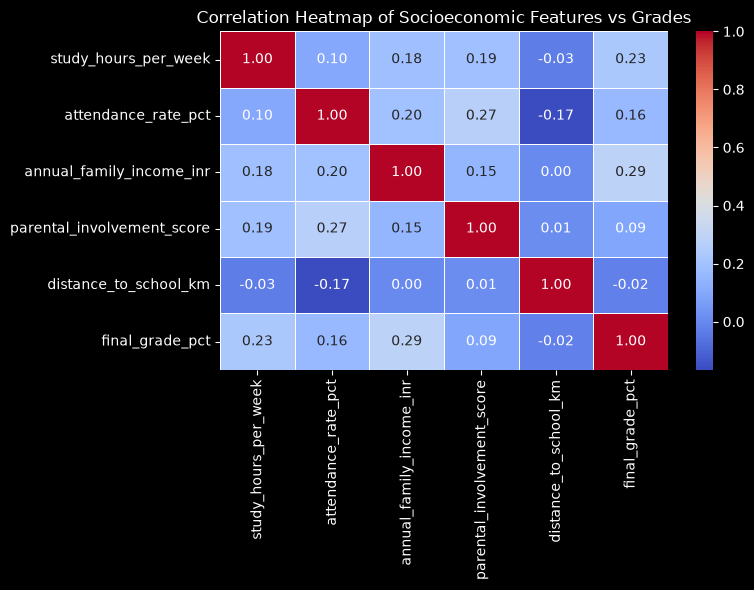

In [31]:

import seaborn as sns

plt.figure(figsize=(8, 6))
# Calculate correlation matrix for our specific features
corr_matrix = clean_dataset[features_and_grade].corr()

# Plot the heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Socioeconomic Features vs Grades')
plt.tight_layout()
plt.show()

#  Linear Regression

check for linear relationships among the columns.

In [18]:
import itertools

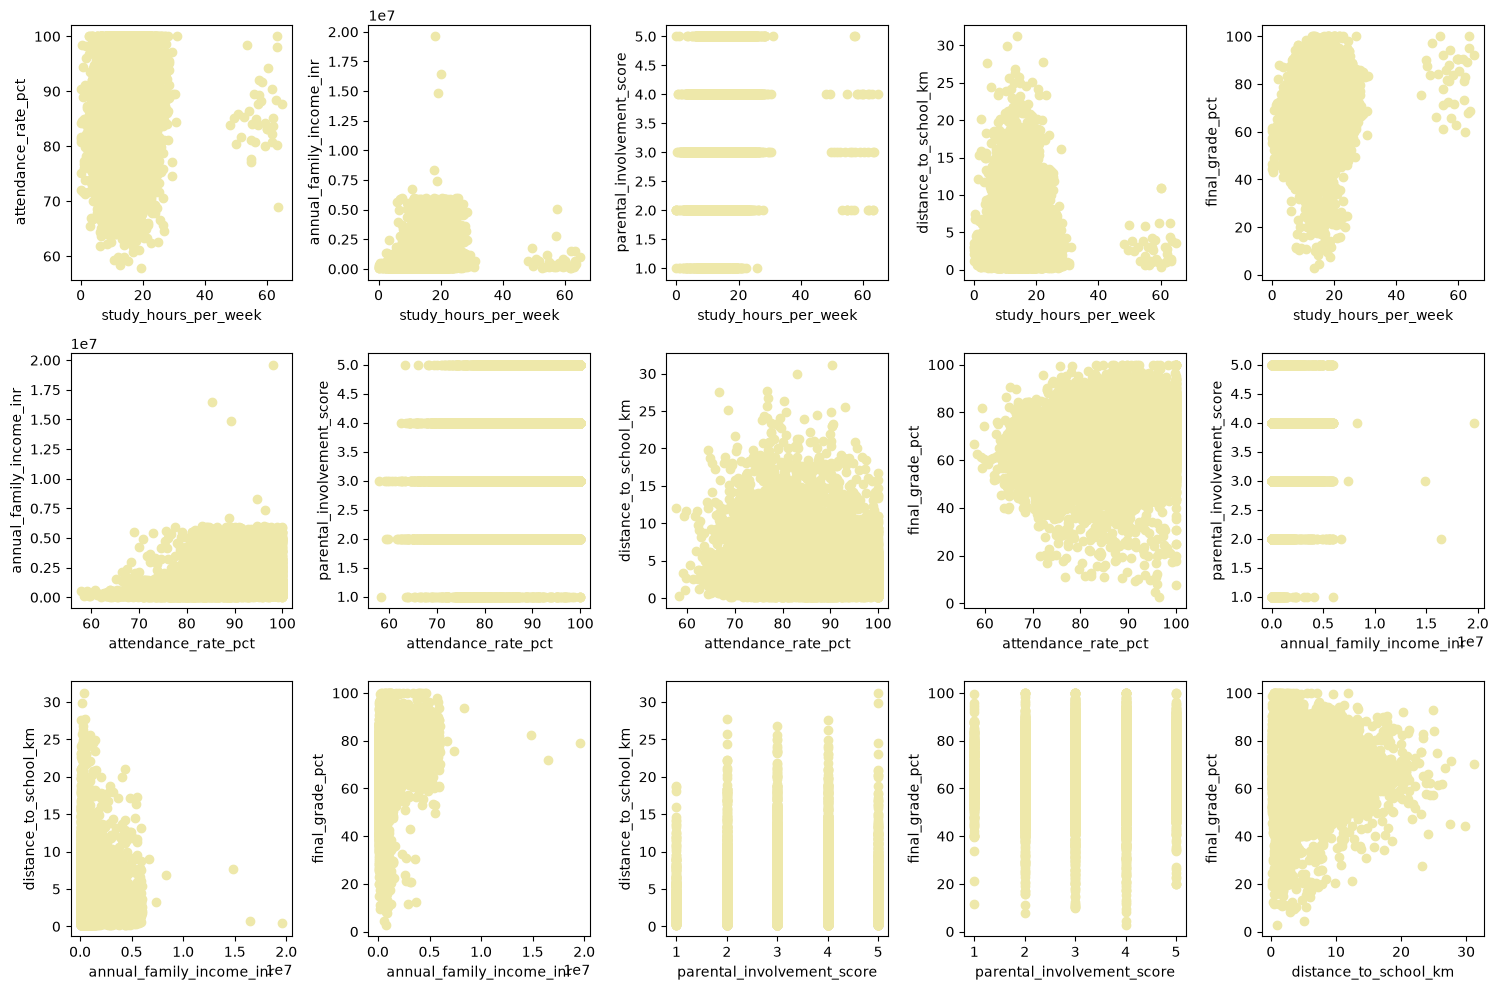

In [19]:
features_and_grade = [
    'study_hours_per_week',
    'attendance_rate_pct',
    'annual_family_income_inr',
    'parental_involvement_score',
    'distance_to_school_km',
    'final_grade_pct'
]

#create all combinations
combinations = itertools.combinations(features_and_grade, 2)
plt.style.use('default')
fig = plt.figure(figsize=(15, 10))
figure_index = 1
for combination in combinations:
    axs = fig.add_subplot(3,5,figure_index)
    #plot the feature combinations
    axs.scatter(dataset[combination[0]], dataset[combination[1]], color='palegoldenrod')
    axs.set_xlabel(combination[0])
    axs.set_ylabel(combination[1])
    figure_index += 1

plt.tight_layout()
plt.show()

In [20]:
#define the x and y values
#X will be the socioeconomic factors listed earlier
clean_dataset = dataset.dropna(subset=features_and_grade)
features= [
    'study_hours_per_week',
    'attendance_rate_pct',
    'annual_family_income_inr',
    'parental_involvement_score',
    'distance_to_school_km'
]
X = clean_dataset[features]
y = clean_dataset['final_grade_pct']

In [21]:
# initialize and fit the model
#splitting the dataset into 80 train and 20 test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0.4 , 0.15, 0. , 0.01,-0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['study_hours_per_week','attendance_rate_pct','annual_family_income_inr', 'parental_involvement_score','distance_to_school_km']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,46.21
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


### Evaluating linear regression using r squared and mean absolute error

In [22]:
y_pred=model.predict(X_test)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

#model evaluation using r squared
print("Linear Regression Results")
r2 = r2_score(y_test, y_pred)
print(f'R_squared: {r2}')

#model evaluation using mean absolute error
mae = mean_absolute_error(y_test, y_pred)
print(f'Mean absolute error: {mae}')

Linear Regression Results
R_squared: 0.10261483399601057
Mean absolute error: 8.667514546615354


### Interpretation of model evaluation:
1. R-squared: An r-squared vaue of ~0.1026 means the socioeconmic features I selected explained around 10.2% of the variance in the student's final grade. The remaining 89.8% is explained by other factors not included in this model. This means the specific socioeconomic and behavioral factors are not strong predictors of the students grade. My initial hypothesis was these features would be moderately predict a student grades, however, academic performance is complex and goes beyond resources, parental involvement, etc.
2. MAE: The main of ~8.66 means the model tried to guess the student's grade using income, study hours, attendance, but its guess is off by an average of 8.66 percentage points

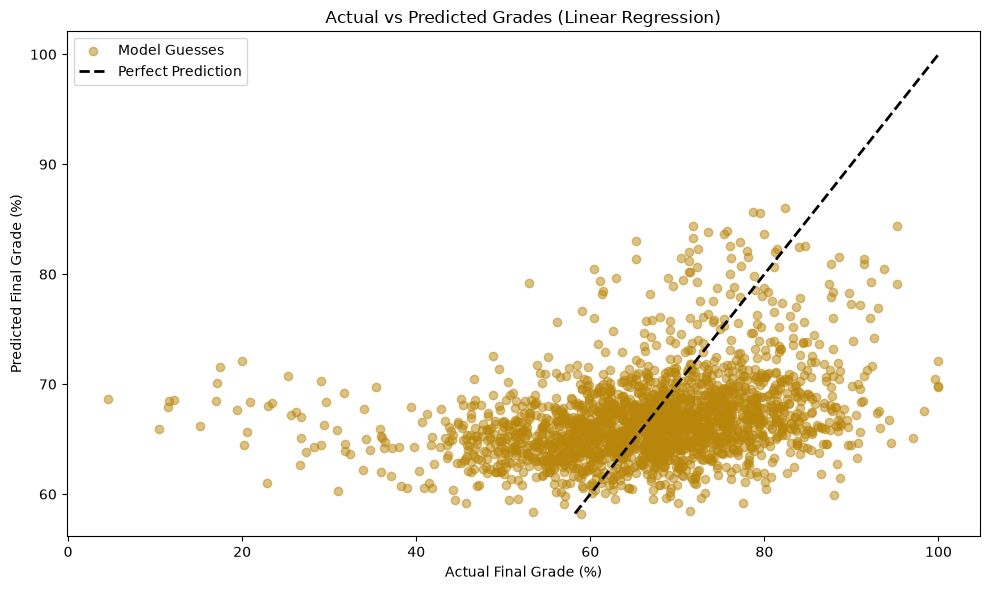

In [23]:
# visualizing the regression
plt.style.use('default')
plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.5, color = 'darkgoldenrod', label='Model Guesses')
max_val=max(y_test.max(), y_pred.max())
min_val=max(y_test.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.title('Actual vs Predicted Grades (Linear Regression)')
plt.xlabel('Actual Final Grade (%)')
plt.ylabel('Predicted Final Grade (%)')
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')


print("5-Fold Cross-Validation (Linear Regression)")
print(f"Individual scores for all 5 folds: {cv_scores}")
print(f"Average Cross-Validation R-squared: {cv_scores.mean():.4f}")

5-Fold Cross-Validation (Linear Regression)
Individual scores for all 5 folds: [0.13476293 0.13627021 0.1042984  0.10620064 0.13034309]
Average Cross-Validation R-squared: 0.1224


Intepretation: Average r-squared across all five folds was 12.2%. My original hold out method of 80 and 20 was 10.2%. Overall, the two numbers are relatively close and the cross validation confirmed the stability of the multiple linear regression model. The R-squared scores remained consistent across the 5 data splits, proving the baseline score was not a result of anomalous train and test split.

# KNN Regression

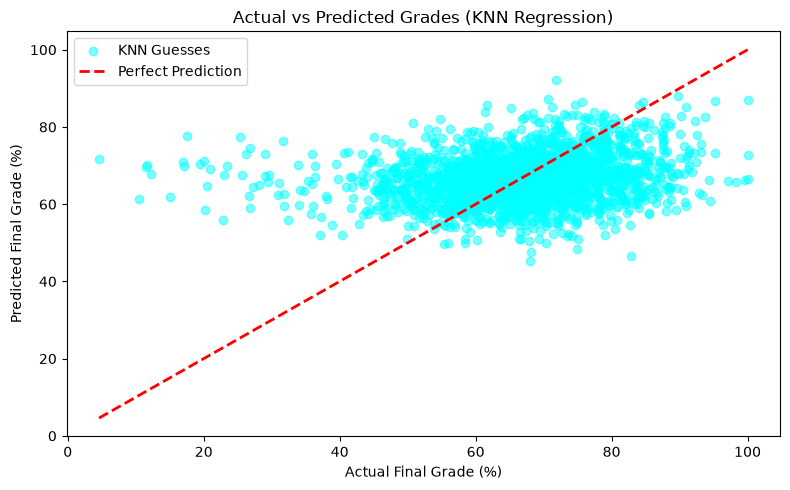

In [25]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

#scale features and fit knn regresspr

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_regressor = KNeighborsRegressor(n_neighbors=5)
knn_regressor.fit(X_train_scaled, y_train)


#make predicitions for the test data
predicition = knn_regressor.predict(X_test_scaled)



plt.style.use('default')
plt.figure(figsize=(8,5))

# Plot the Actual Grades (y_test) vs the KNN Model's Guesses (prediction)
plt.scatter(y_test, predicition, alpha=0.5, color='cyan', label='KNN Guesses')

# Draw the perfect prediction line
max_val = max(y_test.max(), predicition.max())
min_val = min(y_test.min(), predicition.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Actual vs Predicted Grades (KNN Regression)')
plt.xlabel('Actual Final Grade (%)')
plt.ylabel('Predicted Final Grade (%)')
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
r2_knn = r2_score(y_test, predicition)
mae_knn = mean_absolute_error(y_test, predicition)

# Print the results
print("KNN Regression Results")
print(f"R-squared: {r2_knn:.4f}")
print(f"Mean Absolute Error: {mae_knn:.4f}")

KNN Regression Results
R-squared: -0.0573
Mean Absolute Error: 9.4546


Interpretation: From the KNN regression scatter chart, the model's predicitions clustered in between 60%-80% on the y-axis. This means regardless of what the student's grade was, the model frequently guessed the score was somewhere in that middle range. The model struggled to guess with outliers like around <20% (low scores), and >90% (high scores). Because the data points do not perfectly algin with the "perfect prediction" line, the selected socioeconomic and behavioral features were not strong predictors for the student's grades. The negative r-squared of -0.0573 indicated the KNN model performed worse than if it had just guessed the average each time. The noise in the dataset could have contributed to active mistakes. For the mean Absolute Error (9.4546), the KNN model guess was off by around 9.45 percentage points.  Since KNN relies on physical distance between data points, human behavior and socioeconomic status are complex so trying to find "similar neighbors" was difficult and created noise.

# Random Forest Regression

In [27]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# fitting the whole model because Random Forests don't need scaling
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

#Evaluate using the exact same metrics (r squared and mae)
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest Regression Results")
print(f"R-squared: {r2_rf}")
print(f"Mean Absolute Error: {mae_rf}")

Random Forest Regression Results
R-squared: 0.03058026292913718
Mean Absolute Error: 8.96144351851852


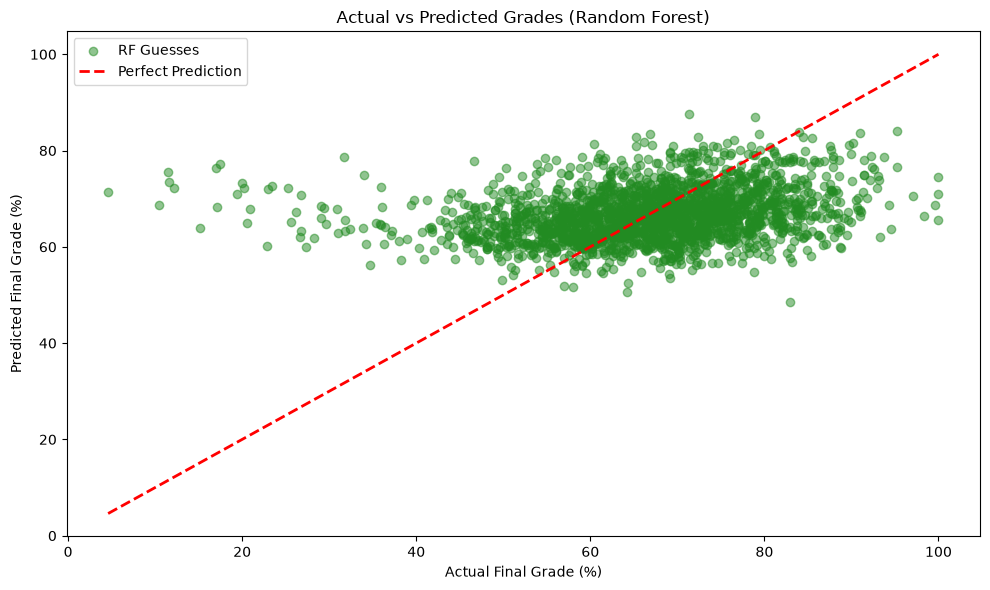

In [28]:
plt.style.use('default')
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.5, color='forestgreen', label='RF Guesses')

max_val = max(y_test.max(), y_pred_rf.max())
min_val = min(y_test.min(), y_pred_rf.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Actual vs Predicted Grades (Random Forest)')
plt.xlabel('Actual Final Grade (%)')
plt.ylabel('Predicted Final Grade (%)')
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/88/6vpwfkkx3j5gd78mb4zmk8t00000gn/T/ipykernel_15729/1704404812.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


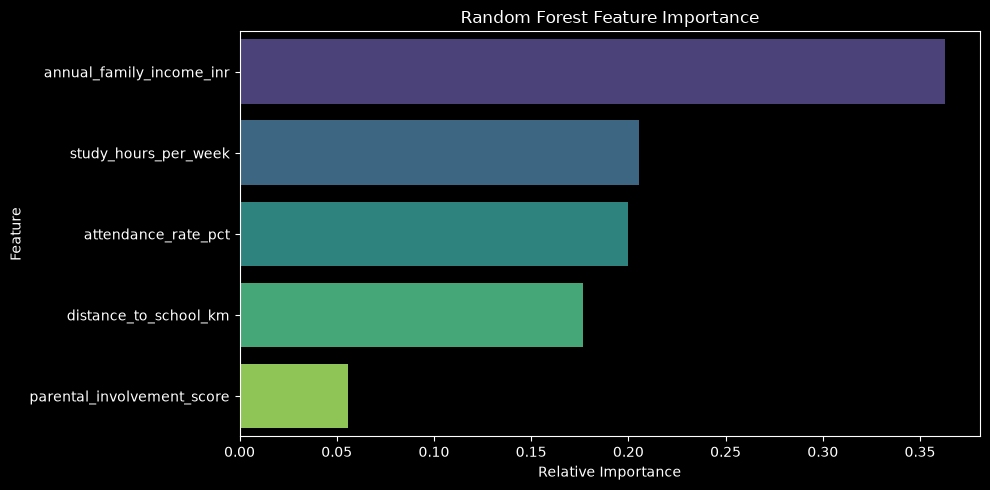

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Extract feature importances from the fitted Random Forest
importances = rf_model.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.style.use('dark_background')
plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

### Requirement #6: Using Generative AI to Improve the Model

I used Generative AI to write a `GridSearchCV` script.This script systematically tests different parameter combinations for the Random Forest to find the best settings, improving the model's accuracy beyond its default state


In [30]:

from sklearn.model_selection import GridSearchCV

# Define the settings we want the AI to test
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

# Set up the Grid Search for the Random Forest
grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42),
                           param_grid=param_grid,
                           cv=3,
                           scoring='r2',
                           n_jobs=-1)

# Fit it to the data to find the best combination
grid_search.fit(X_train, y_train)
best_rf_model = grid_search.best_estimator_
optimized_pred = best_rf_model.predict(X_test)

print("--- AI-Optimized Random Forest ---")
print(f"Best Parameters Found: {grid_search.best_params_}")
print(f"Optimized R-squared: {r2_score(y_test, optimized_pred):.4f}")
print(f"Optimized MAE: {mean_absolute_error(y_test, optimized_pred):.4f}")

--- AI-Optimized Random Forest ---
Best Parameters Found: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
Optimized R-squared: 0.1121
Optimized MAE: 8.6006
